Tutorial: shells pressed down by a prescribed displacement, Riks' method
===

Two shells are pressed down by a deflection prescribed at their centre,
without any applied load, and the reaction is traced against the
deflection with Riks' arc-length method of `pyfe3d.solver`, with
`Analysis(..., bu=bu, uk=uk)` and `calc_fext` returning zeros, see the user
guide page *Non-linear static analyses*. The non-linear reaction is
compared with the linear one and with published results:

1. A deep clamped spherical cap driven far past its inversion, the
   benchmark of Lyons, P. and Holsgrove, S., *Finite Element Benchmarks
   for 2D Beams and Axisymmetric Shells Involving Geometric
   Non-Linearity*, NAFEMS, 2005 (no DOI), whose reference values are
   tabulated in the open verification model COMSOL, *Spherical Cap with
   Central Point Load*, COMSOL Multiphysics 6.4, Application Library,
   Structural Mechanics Module, Verification Examples,
   [doc.comsol.com](https://doc.comsol.com/6.4/doc/com.comsol.help.models.sme.spherical_cap_with_central_point_load/models.sme.spherical_cap_with_central_point_load.pdf):
   the problem on p. 2, the reference values in Tables 1 to 4, pp. 6-7,
   the parameters and nondimensional variables on p. 9, the geometry on
   pp. 9-10 and the shell offset on p. 13. The whole path shows where the
   von Kármán strains of the pyfe3d shells stop being valid; a separate
   comparison is restricted to the moderate rotations.
2. A hinged shallow spherical shell on a square base, whose snap-through
   stays within moderate rotations: Fig. 17 (p. 33) of Horrigmoe, G. and
   Bergan, P. G., Nonlinear analysis of free-form shells by flat finite
   elements, *Computer Methods in Applied Mechanics and Engineering*,
   16(1), 11-35, 1978,
   [doi:10.1016/0045-7825(78)90030-0](https://doi.org/10.1016/0045-7825(78)90030-0),
   and Fig. 4 (p. 1688) of Bergan, P. G., Horrigmoe, G., Krakeland, B. and
   Soreide, T. H., Solution techniques for non-linear finite element
   problems, *International Journal for Numerical Methods in Engineering*,
   12(11), 1677-1696, 1978,
   [doi:10.1002/nme.1620121106](https://doi.org/10.1002/nme.1620121106),
   both with the series solution of Leicester, R. H., Finite deformations
   of shallow shells, *Journal of the Engineering Mechanics Division,
   ASCE*, 94(EM6), 1409-1423, 1968 (not consulted here; read from the
   figures).

The arc-length method is that of Riks, E., An incremental approach to the
solution of snapping and buckling problems, *International Journal of
Solids and Structures*, 15(7), 529-551, 1979,
[doi:10.1016/0020-7683(79)90081-7](https://doi.org/10.1016/0020-7683(79)90081-7).

The models are built by the functions of
`tests/test_dome_prescribed_displacement.py`, which also runs the checks of
this notebook as tests. Each case has one function returning its path for
a given formulation, collected in the dictionary `FORMULATIONS`: the
von Kármán strains of the elements, `cap_path` and `leicester_path`, and
the co-rotational kinematics of `pyfe3d.corotational.CorotationalModel`
with `kinematics='corotational'`, valid for large rotations with small
strains, `cap_path_cr` and `leicester_path_cr`, both with `Quad4R`. The
co-rotational paths are compared with the references in the sections
*Large rotations: the co-rotational kinematics* of each case.

The cells below run in about seven minutes.

In [1]:
import os
import sys
import time
sys.path.insert(0, os.path.join('..', '..'))
sys.path.insert(0, os.path.join('..', '..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt

import pyfe3d
from pyfe3d import DOF
from pyfe3d.solver import solve
from test_dome_prescribed_displacement import (CAP, TABLE_SHELL_REF,
    TABLE_SHELL_COMSOL16, TABLE_SOLID_REF, LEICESTER, LEICESTER_RISING,
    LEICESTER_UPPER, LEICESTER_LOWER, HORRIGMOE_LIMIT_LOADS, cap_model,
    leicester_model, load_factor, run_cap, run_leicester, limit_points,
    line_y0, meridian_rotation, compare, run_cap_corotational,
    run_leicester_corotational, branches)

print('pyfe3d', pyfe3d.__version__, 'from', os.path.dirname(pyfe3d.__file__))
a, th = CAP['a'], CAP['th']

pyfe3d 0.12.0 from C:\Users\saullogiovanip\repos\pyfe3d\doc\source\..\..\pyfe3d


In [2]:
def rotations(p):
    # NOTE largest change of slope of the line Y = 0 at each point of the path
    line = line_y0(p['model'])
    return np.array([0.] + [meridian_rotation(p['model'], c, line)
                            for c in p['an'].cs])


def cap_path(n, R, **kwargs):
    r"""Path of the cap with n x n cells per block and mid-surface radius R:
    w/th, F_n, the linear slope, the rotations and the analysis"""
    w, Fn, slope, an, model, dofw = run_cap(n, R, **kwargs)
    p = dict(w=w, F=Fn, slope=slope, an=an, model=model, dofw=dofw)
    p['rot'] = rotations(p)
    return p


def leicester_path(n, shear_factor=1., **kwargs):
    r"""Path of the hinged shell with n x n cells on the quarter: w [mm],
    P [kN], the linear slope [kN/mm], the rotations and the analysis"""
    w, P, slope, an, model, dofw = run_leicester(n, shear_factor, **kwargs)
    p = dict(w=w, F=P, slope=slope, an=an, model=model, dofw=dofw)
    p['rot'] = rotations(p)
    return p


def cap_path_cr(n, R, **kwargs):
    r"""As cap_path, with Quad4R and kinematics='corotational'"""
    w, Fn, slope, an, model, dofw = run_cap_corotational(n, R, **kwargs)
    p = dict(w=w, F=Fn, slope=slope, an=an, model=model, dofw=dofw)
    p['rot'] = rotations(p)
    return p


def leicester_path_cr(n, shear_factor=1., **kwargs):
    r"""As leicester_path, with Quad4R and kinematics='corotational'"""
    w, P, slope, an, model, dofw = run_leicester_corotational(n, shear_factor, **kwargs)
    p = dict(w=w, F=P, slope=slope, an=an, model=model, dofw=dofw)
    p['rot'] = rotations(p)
    return p


#: one entry per shell formulation
FORMULATIONS = {'von Kármán': dict(cap=cap_path, leicester=leicester_path),
                'co-rotational': dict(cap=cap_path_cr, leicester=leicester_path_cr)}

1. The clamped spherical cap (NAFEMS)
===

The benchmark
---

From the COMSOL model: radius $a = 10$ m, thickness $t_h = 0.20384$ m,
sector (half-)angle $\pi/4$, edge fixed (p. 2); $E = 210$ GPa,
$\nu = 0.3$ (p. 9). The results are given with the nondimensional load and
crown deflection (p. 9)

$$
F_n = \frac{F a}{2 \pi E t_h^3}, \qquad \frac{w}{t_h}
$$

with $F$ the point load on the whole cap and $w$ the downward deflection of
the crown. Tables 3 and 4 (p. 7), with 8 and 16 axisymmetric shell
elements, list the same reference values of Lyons and Holsgrove (2005), the
deflection at seven loads, together with the deflections computed by COMSOL
at the same loads; Table 1 (p. 6) lists the reference values of a solid
model. The reference load rises to 1.757 at $w/t_h = 20.887$, passes a
maximum that is not tabulated, drops to 1.678 at $w/t_h = 25.668$ and then
rises steeply, the cap being inverted. COMSOL's shell with 16 elements
gives 1.806 at $w/t_h = 23.06$, near its maximum, and 1.717 at 25.51, near
its minimum (Fig. 3, p. 5, and Fig. 4, p. 6), and COMSOL notes that a
refined solid model supports its own values rather than the reference
(p. 8). COMSOL's deflections are 0.5 to 5 % larger than the reference,
e.g. 2.445 against 2.326 at the first load, the scatter of the published
results.

**Geometry.** The COMSOL geometry is a circular arc of radius $a + t_h$
with one layer of thickness $t_h$ (pp. 9-10), i.e. the solid spans the
radii $a$ to $a + t_h$, and the shell is given the offset "Top surface on
boundary" with $d_0 = t_h$, "to model the solid midplane" (p. 13): COMSOL's
shell mid-surface radius is $a + t_h/2$. Whether the reference of Lyons and
Holsgrove (2005), not available here, takes $a$ as the mid-surface radius
or as the inner radius is not known. Both are computed below, the
mid-surface radius $R = a$ and $R = a + t_h/2$, always with $a = 10$ m in
$F_n$.

**Tolerance.** 5 % on the load at the deflections of the reference, the
published results scattering by about 4 %.

In [3]:
TOL = 0.05
print('Tables 3 and 4: reference (Lyons and Holsgrove) and COMSOL 16 shell elements')
print('%8s %10s %14s' % ('F_n', 'w/th ref', 'w/th COMSOL16'))
for (F, w), (Fc, wc) in zip(TABLE_SHELL_REF, TABLE_SHELL_COMSOL16):
    print('%8.3f %10.3f %8.3f%s' % (F, w, wc, '' if Fc == F else ' (at F_n = %.3f)' % Fc))
print('rise of the cap a (1 - cos 45 deg) = %.3f m = %.1f th'
      % (a*(1 - np.cos(CAP['alpha'])), a*(1 - np.cos(CAP['alpha']))/th))

Tables 3 and 4: reference (Lyons and Holsgrove) and COMSOL 16 shell elements
     F_n   w/th ref  w/th COMSOL16
   0.332      2.326    2.445
   0.580      6.720    6.800
   0.994     13.642   13.800
   1.502     18.487   18.945
   1.757     20.887   21.640
   1.678     25.668   25.500 (at F_n = 1.717)
   3.705     28.680   29.410
rise of the cap a (1 - cos 45 deg) = 2.929 m = 14.4 th


The last reference point, $w/t_h = 28.68$, is about twice the rise of the
cap: the cap is driven to its mirror image.

The model
---

The deformation is axisymmetric; one quarter of the cap is modelled, with
the symmetry conditions $u = r_y = r_z = 0$ on the plane $X = 0$ and
$v = r_x = r_z = 0$ on $Y = 0$, the edge clamped (all six dofs), and the
crown deflection $w$ prescribed: it is a known dof, `bu[dofw] = False`,
with `uk[dofw]` $= -30\, t_h$ at the load factor $\lambda = 1$. The quarter
disc is meshed with three blocks of $n \times n$ cells, a square around the
crown and two blocks up to the edge, mapped to the sphere at the polar
angle $\beta = \rho \pi/4$, where $\rho$ is the distance to the crown in
the disc; along the meridians on the planes of symmetry there are $2 n$
elements. Each cell is split into two `Tria3R` along alternating
diagonals, see *Choosing an element* for the element and the next section
for why it is used here.

There is no load: `calc_fext` of `Model` returns the zero vector and the
analysis is displacement controlled, the prescribed deflection growing as
$\lambda$ `uk`. The reaction of the quarter at the crown is
`calc_fint(u)[dofw]`, which is multiplied by 4 for the whole cap. For the
linear analysis, `static(NLgeom=False)`, the reaction is
$\boldsymbol{K}_{C0} \boldsymbol{u}$ at that dof: `calc_fint` of `Model`
gives the non-linear internal forces.

16x16 cells: 1536 Tria3R, 817 nodes, 4902 dofs, 4512 free


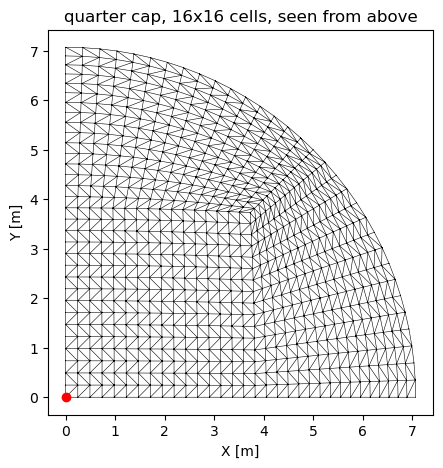

In [4]:
model, bu, dofw = cap_model(16, a)
print('16x16 cells: %d Tria3R, %d nodes, %d dofs, %d free' % (
    len(model.elements), model.N//DOF, model.N, bu.sum()))
xyz = model.x.reshape(-1, 3)
fig, ax = plt.subplots(figsize=(5, 5))
tri = np.array([[e.n1, e.n2, e.n3] for e in model.elements])
ax.triplot(xyz[:, 0], xyz[:, 1], tri, 'k-', lw=0.4)
ax.plot(0, 0, 'ro')
ax.set_aspect('equal')
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_title('quarter cap, 16x16 cells, seen from above')
plt.show()

Choice of element
---

The point load makes the crown the critical region; its elements are the
smallest of the mesh, of the order of the thickness. The linear crown
stiffness, the slope $\mathrm{d}F_n/\mathrm{d}(w/t_h)$, against the mesh,
for `Quad4` (the recommended quadrilateral) and `Tria3R` (the recommended
triangle):

In [5]:
def linear_slope(n, R, element):
    model, bu, dofw = cap_model(n, R, element)
    K = model.KC0
    bk = ~bu
    u = np.zeros(model.N)
    u[dofw] = -th
    u[bu] = solve(K[bu][:, bu], -K[bu][:, bk] @ u[bk])
    return load_factor(-4*(K @ u)[dofw])

meshes = [8, 12, 16, 20, 24, 32]
slopes = {}
print('%5s | %8s | %8s' % ('n', 'Quad4', 'Tria3R'))
for n in meshes:
    sq = linear_slope(n, a, 'Quad4')
    st = linear_slope(n, a, 'Tria3R')
    slopes[n] = (sq, st)
    print('%5d | %8.4f | %8.4f' % (n, sq, st))
sq = np.array([slopes[n][0] for n in meshes])
st = np.array([slopes[n][1] for n in meshes])
assert np.all(np.diff(sq) < 0) and np.all(np.diff(st) < 0) # both monotonic

    n |    Quad4 |   Tria3R
    8 |   0.3802 |   0.4107


   12 |   0.3675 |   0.3847


   16 |   0.3618 |   0.3740


   20 |   0.3585 |   0.3682


   24 |   0.3562 |   0.3644


   32 |   0.3531 |   0.3598


Both elements converge monotonically, from above: `Quad4`, whose
transverse shear uses the assumed strains of the MITC4 element at any
thickness (see the Notes of `pyfe3d.quad4`), from 0.3802 with 8x8 cells to
0.3531 with 32x32, and `Tria3R` from 0.4107 to 0.3598, 1.9 % stiffer than
`Quad4` on the finest mesh. `Tria3R` is used below, as in the tests. The slow decrease that
remains is expected: under a point load the transverse shear force is
$Q = F/(2 \pi r)$ near the load, from the vertical equilibrium of a disc of
radius $r$, so that with a finite transverse shear stiffness the shear
deflection grows as $\ln r$, and the deflection under the load of a
shear-deformable shell is singular; the mesh resolves it only
logarithmically.

Riks' arc-length method
---

`NL_method = 'arc_length_riks'`, `initialInc = maxInc = 0.02`: the first
arc length corresponds to the load factor increment 0.02 along the initial
tangent, $\Delta (w/t_h) = 0.6$, and the arc length is not allowed to grow
beyond it, such that the path is sampled finely enough to interpolate it at
the reference deflections. `maxArcLength` is raised such that the analysis
stops only at $\lambda = 1$, $w/t_h = 30$. The crown deflection grows
monotonically here, so displacement control alone would also pass the limit
load of the reaction; the arc-length method would also follow a path whose
prescribed deflection turns back. The analysis is run for the two
mid-surface radii with 16x16 cells, with the von Kármán strains of the
elements; the co-rotational kinematics follow in a later section.

In [6]:
cap_paths = {}
for form in ['von Kármán']:
    funcs = FORMULATIONS[form]
    for label, R in [('R = a', a), ('R = a + th/2', a + th/2)]:
        t0 = time.time()
        p = funcs['cap'](16, R)
        cap_paths[form, label] = p
        print('%s, %-13s: %d increments, last load factor %.3f, w/th = %.2f, '
              'linear slope %.4f, %.0f s' % (form, label, len(p['an'].increments),
              p['an'].increments[-1], p['w'][-1], p['slope'], time.time() - t0))
        assert p['an'].increments[-1] == 1.
        assert np.all(np.diff(p['w']) > 0)

von Kármán, R = a        : 127 increments, last load factor 1.000, w/th = 30.00, linear slope 0.3740, 74 s


von Kármán, R = a + th/2 : 127 increments, last load factor 1.000, w/th = 30.00, linear slope 0.3706, 72 s


The whole path
---

The path is interpolated linearly at the deflections of the reference, and
the relative difference of the load is listed with the largest rotation of
the meridian $Y = 0$ at that point, the largest change of slope of the
segments between its nodes, from their deformed positions:

In [7]:
rel = {k: compare(p['w'], p['F']) for k, p in cap_paths.items()}
rot_ref = {k: np.interp(TABLE_SHELL_REF[:, 1], p['w'], p['rot']) for k, p in cap_paths.items()}
keys = list(cap_paths)
print('%8s %8s | %s' % ('w/th', 'F_n ref', ' | '.join('%26s' % ('%s, %s' % k) for k in keys)))
for i, (F, w) in enumerate(TABLE_SHELL_REF):
    vals = ['%8.4f %+6.1f %% %5.0f deg' % (F*(1 + rel[k][i]), 100*rel[k][i], rot_ref[k][i])
            for k in keys]
    print('%8.3f %8.3f | %s' % (w, F, ' | '.join(vals)))

    w/th  F_n ref |          von Kármán, R = a |   von Kármán, R = a + th/2
   2.326    0.332 |   0.3345   +0.8 %    14 deg |   0.3313   -0.2 %    14 deg
   6.720    0.580 |   0.5787   -0.2 %    30 deg |   0.5733   -1.2 %    30 deg
  13.642    0.994 |   0.9229   -7.1 %    50 deg |   0.9115   -8.3 %    49 deg
  18.487    1.502 |   1.2337  -17.9 %    62 deg |   1.2139  -19.2 %    62 deg
  20.887    1.757 |   1.4145  -19.5 %    68 deg |   1.3925  -20.7 %    67 deg
  25.668    1.678 |   1.7068   +1.7 %    78 deg |   1.6931   +0.9 %    77 deg
  28.680    3.705 |   1.7416  -53.0 %    86 deg |   1.7428  -53.0 %    85 deg


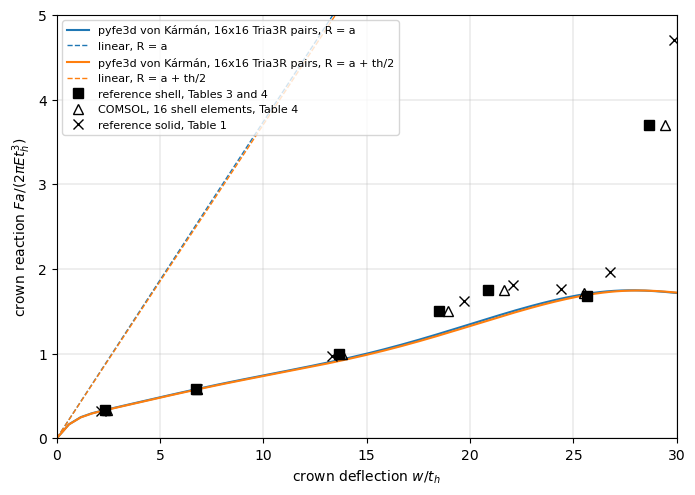

In [8]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for (k, p), c in zip(cap_paths.items(), ['C0', 'C1', 'C2', 'C3']):
    ax.plot(p['w'], p['F'], '-', color=c, lw=1.5,
            label='pyfe3d %s, 16x16 Tria3R pairs, %s' % k)
    ax.plot([0, 30], [0, 30*p['slope']], '--', color=c, lw=1,
            label='linear, %s' % k[1])
ax.plot(TABLE_SHELL_REF[:, 1], TABLE_SHELL_REF[:, 0], 'ks', ms=7,
        label='reference shell, Tables 3 and 4')
ax.plot(TABLE_SHELL_COMSOL16[:, 1], TABLE_SHELL_COMSOL16[:, 0], 'k^',
        mfc='none', ms=7, label='COMSOL, 16 shell elements, Table 4')
ax.plot(TABLE_SOLID_REF[:, 1], TABLE_SOLID_REF[:, 0], 'kx', ms=7,
        label='reference solid, Table 1')
ax.set_xlim(0, 30)
ax.set_ylim(0, 5)
ax.set_xlabel('crown deflection $w/t_h$')
ax.set_ylabel(r'crown reaction $F a/(2 \pi E t_h^3)$')
ax.legend(loc='upper left', fontsize=8)
ax.grid(True, lw=0.3)
plt.show()

The non-linear reaction falls below the linear one from the start: the cap
softens. Up to $w/t_h = 6.72$ the path agrees with the reference; at
$w/t_h = 13.64$ it is more than 5 % below, then about 20 % below before
the limit load of the reference, and pyfe3d does not find the steep
stiffening of the inverted cap: the last reference point, $F_n = 3.705$ at
$w/t_h = 28.68$, is about twice the computed load. The solver itself
reaches $w/t_h = 30$, the load factor 1.0; the departure comes from the
kinematics of the elements.

The shell elements of pyfe3d use the von Kármán membrane strains in the
frame of each undeformed element, valid for moderate rotations, see
*Choosing an element* and the cantilever under an end moment in
*Geometrically non-linear benchmarks*. The rotations listed above exceed
30 degrees beyond $w/t_h \approx 7$, where the path starts to depart from
the reference, and reach 85 degrees when the cap is inverted: far outside
the range of the von Kármán strains, and a shell formulation for large
rotations is needed for the whole path, see the co-rotational kinematics
below. The largest circumferential
displacement over the crown deflection, which vanishes for an axisymmetric
deformation, and the deformed meridian, without amplification:

largest |u_t|/w along the path: 2.0e-03


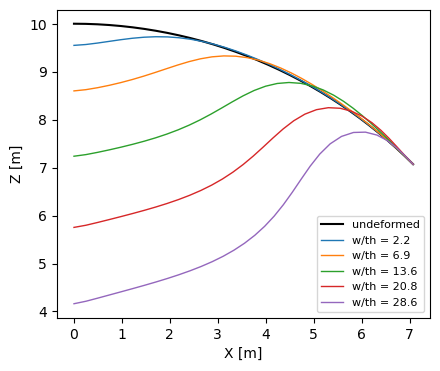

In [9]:
p = cap_paths['von Kármán', 'R = a']
model, an, dofw = p['model'], p['an'], p['dofw']
xyz = model.x.reshape(-1, 3)
rho = np.hypot(xyz[:, 0], xyz[:, 1])
ut_max = max(np.abs((-c.reshape(-1, DOF)[:, 0]*xyz[:, 1]
                     + c.reshape(-1, DOF)[:, 1]*xyz[:, 0])/np.where(rho > 0, rho, 1.)).max()
             /abs(c[dofw]) for c in an.cs)
print('largest |u_t|/w along the path: %.1e' % ut_max)
assert ut_max < 1e-2
meridian = line_y0(model)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(xyz[meridian, 0], xyz[meridian, 2], 'k-', lw=1.5, label='undeformed')
for (F, wr), c in zip(TABLE_SHELL_REF[[0, 1, 2, 4, 6]], ['C0', 'C1', 'C2', 'C3', 'C4']):
    i = int(np.argmin(abs(p['w'][1:] - wr)))
    u = an.cs[i].reshape(-1, DOF)
    ax.plot(xyz[meridian, 0] + u[meridian, 0], xyz[meridian, 2] + u[meridian, 2],
            '-', color=c, lw=1, label='w/th = %.1f' % p['w'][i + 1])
ax.set_aspect('equal')
ax.set_xlabel('X [m]')
ax.set_ylabel('Z [m]')
ax.legend(fontsize=8)
plt.show()

The moderate-rotation range
---

The comparison with the reference is restricted here to the points where
the largest rotation of the meridian is below 35 degrees. The rotations at
the reference points, listed above, give this range: $w/t_h = 2.326$ and
6.720, with 14 and 30 degrees. The point $w/t_h = 13.64$ is not included:
its rotation is about 50 degrees, and its load is 7 to 8 % below the
reference, outside the tolerance; any limit between 30 and 50 degrees
gives the same two points. The tolerance is 5 %, as above. The lower plot
shows the largest rotation along the path: the 30 degrees are reached at
$w/t_h \approx 6.8$.

von Kármán, R = a: points [2.326 6.72 ] within 5 %: +0.8 %, -0.2 %
von Kármán, R = a + th/2: points [2.326 6.72 ] within 5 %: -0.2 %, -1.2 %


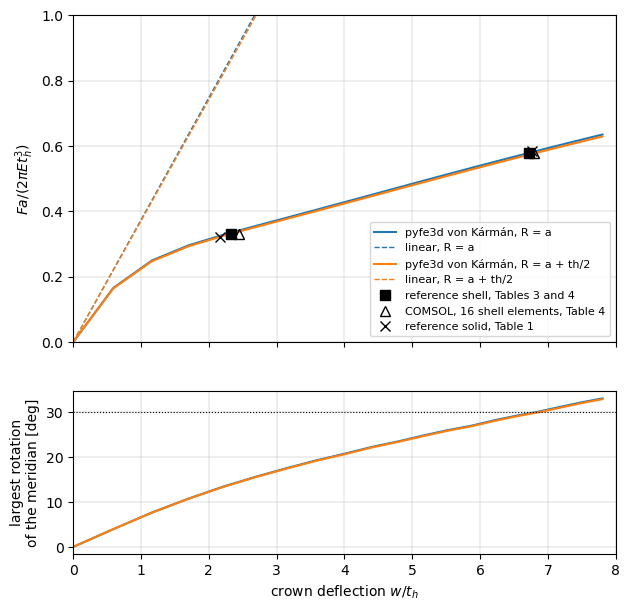

In [10]:
ROT_LIMIT = 35.
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True,
                              gridspec_kw=dict(height_ratios=[2, 1]))
for (k, p), c in zip(cap_paths.items(), ['C0', 'C1', 'C2', 'C3']):
    inside = rot_ref[k] < ROT_LIMIT
    assert np.all(np.abs(rel[k][inside]) < TOL), (k, rel[k])
    print('%s, %s: points %s within %.0f %%: %s' % (k + (
        TABLE_SHELL_REF[inside, 1], 100*TOL, ', '.join('%+.1f %%' % (100*r)
                                                       for r in rel[k][inside]))))
    m = p['w'] <= 8.
    ax.plot(p['w'][m], p['F'][m], '-', color=c, lw=1.5, label='pyfe3d %s, %s' % k)
    ax.plot([0, 8], [0, 8*p['slope']], '--', color=c, lw=1, label='linear, %s' % k[1])
    ax2.plot(p['w'][m], p['rot'][m], '-', color=c, lw=1.5)
inside = rot_ref[keys[0]] < ROT_LIMIT
assert inside.sum() == 2
ax.plot(TABLE_SHELL_REF[:2, 1], TABLE_SHELL_REF[:2, 0], 'ks', ms=7,
        label='reference shell, Tables 3 and 4')
ax.plot(TABLE_SHELL_COMSOL16[:2, 1], TABLE_SHELL_COMSOL16[:2, 0], 'k^',
        mfc='none', ms=7, label='COMSOL, 16 shell elements, Table 4')
ax.plot(TABLE_SOLID_REF[:2, 1], TABLE_SOLID_REF[:2, 0], 'kx', ms=7,
        label='reference solid, Table 1')
ax.set_ylim(0, 1.)
ax.set_ylabel(r'$F a/(2 \pi E t_h^3)$')
ax.legend(fontsize=8)
ax.grid(True, lw=0.3)
ax2.axhline(30., color='k', lw=0.8, ls=':')
ax2.set_xlim(0, 8)
ax2.set_xlabel('crown deflection $w/t_h$')
ax2.set_ylabel('largest rotation\nof the meridian [deg]')
ax2.grid(True, lw=0.3)
plt.show()

Mesh convergence
---

The loads at the two points of the moderate-rotation range against the
mesh, for $R = a$, with the analysis stopped at $w/t_h = 7$:

In [11]:
conv = {}
for n in [8, 12, 16, 24]:
    t0 = time.time()
    w, Fn, slope, an, model, dofw = run_cap(n, a, w_max=7., initialInc=0.05,
                                            maxInc=0.05)
    conv[n] = compare(w, Fn)
    print('%2dx%-2d cells: F_n %.4f (%+.1f %%), %.4f (%+.1f %%), %.0f s' % (
        n, n, TABLE_SHELL_REF[0, 0]*(1 + conv[n][0]), 100*conv[n][0],
        TABLE_SHELL_REF[1, 0]*(1 + conv[n][1]), 100*conv[n][1],
        time.time() - t0))
for n in [12, 16, 24]:
    assert np.all(np.abs(conv[n]) < TOL)

 8x8  cells: F_n 0.3571 (+7.5 %), 0.6300 (+8.6 %), 3 s


12x12 cells: F_n 0.3404 (+2.5 %), 0.5922 (+2.1 %), 8 s


16x16 cells: F_n 0.3346 (+0.8 %), 0.5787 (-0.2 %), 18 s


24x24 cells: F_n 0.3302 (-0.6 %), 0.5688 (-1.9 %), 58 s


The loads decrease with the mesh, at $w/t_h = 6.72$ by 6.0, 2.3 and 1.7 %
at each refinement, and are within 5 % of the reference from 12x12 cells;
with 8x8 cells they are 7.5 and 8.6 % too high. Measured separately on
2026-10-30, 32x32 cells give $F_n = 0.3284$ and $0.5650$, -1.1 and -2.6 %,
with $R = a$, and $0.3253$ and $0.5596$, -2.0 and -3.5 %, with
$R = a + t_h/2$. The decrease slows down without stopping, as the linear
crown stiffness above, because of the singular shear deflection under the
point load; within the tolerance, the 16x16 mesh of the whole path
represents the converged values of the moderate-rotation range.

Large rotations: the co-rotational kinematics
---

The co-rotational kinematics, `kinematics='corotational'` of
`CorotationalModel`, remove the rigid rotation of each element before its
linear strains are evaluated, and allow large rotations with small strains;
the nodal rotations are total rotation vectors, valid below one revolution,
far from the rotations of this cap. They are used here with `Quad4R`, whose
quadrilaterals, warped on the sphere, are linked to their nodes with rigid
offsets, the default `warping='offsets'` of `CorotationalShell`. 12x12
cells (432 `Quad4R`), mid-surface radius $R = a$, are used. For a comparison with the same element and mesh, the
von Kármán path of `Quad4R` is traced as well (`run_cap(..., element='Quad4R')`).

Past the limit load the co-rotational crown deflection turns back: Riks'
method follows a path along which the prescribed deflection decreases, a
snap-back of the prescribed degree-of-freedom, before the cap inverts and
the deflection grows again. The path is therefore compared with the
reference on its first branch, up to the first decrease of $w$, and on its
last branch, after the last decrease, with `branches()` of the tests.

**Tolerance**: 5 % on the load at the deflections of the reference, as
above.

co-rotational, 12x12 Quad4R, R = a: 164 increments, last load factor 1.000, 70 s


von Kármán, 12x12 Quad4R, R = a: 126 increments, 31 s
co-rotational: w/th decreases between 24.61 and 22.75
    w/th  F_n ref |  co-rotational, Quad4R |     von Kármán, Quad4R |     von Kármán, Tria3R
   2.326    0.332 |    +0.7 %     14 deg |    +1.2 %            |    +0.8 %
   6.720    0.580 |    +2.1 %     29 deg |    +2.6 %            |    -0.2 %
  13.642    0.994 |    +2.5 %     46 deg |    -2.3 %            |    -7.1 %
  18.487    1.502 |    -0.2 %     55 deg |   -16.4 %            |   -17.9 %
  20.887    1.757 |    -0.5 %     57 deg |   -20.4 %            |   -19.5 %
  25.668    1.678 |    +7.8 %     76 deg |    +0.6 %            |    +1.7 %
  28.680    3.705 |   -15.9 %     79 deg |   -52.2 %            |   -53.0 %
co-rotational limit load 1.895 at w/th = 23.34; COMSOL, 16 shell elements, Fig. 3: 1.806 at 23.06
deflection at the load of the last point, F_n = 3.705: w/th = 29.258 (+2.0 %); reference 28.680, COMSOL 16 elements 29.410


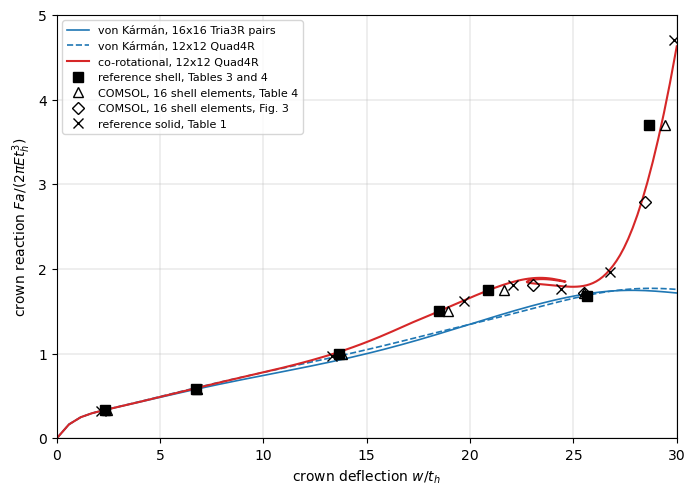

In [12]:
# NOTE COMSOL, 16 shell elements, Fig. 3 (p. 5): F_n and w/th
COMSOL_FIG3 = np.array([[1.806, 23.06], [1.717, 25.51], [2.787, 28.45]])
t0 = time.time()
p = FORMULATIONS['co-rotational']['cap'](12, a)
cap_cr = p
print('co-rotational, 12x12 Quad4R, R = a: %d increments, last load factor %.3f, '
      '%.0f s' % (len(p['an'].increments), p['an'].increments[-1], time.time() - t0))
assert p['an'].increments[-1] == 1.
t0 = time.time()
q = cap_path(12, a, element='Quad4R')
cap_vk_q = q
print('%s, 12x12 Quad4R, R = a: %d increments, %.0f s' % (
    'von Kármán', len(q['an'].increments), time.time() - t0))
first, last = branches(p['w'])
print('co-rotational: w/th decreases between %.2f and %.2f' % (
    p['w'][first][-1], p['w'][last][0]))
rel_cr = np.full(len(TABLE_SHELL_REF), np.nan)
r = compare(p['w'][first], p['F'][first])
rel_cr[:r.size] = r
on_last = TABLE_SHELL_REF[:, 1] >= p['w'][last][0]
rel_cr[on_last] = np.interp(TABLE_SHELL_REF[on_last, 1], p['w'][last],
                            p['F'][last])/TABLE_SHELL_REF[on_last, 0] - 1
rot_cr = np.interp(TABLE_SHELL_REF[:, 1], p['w'][first], p['rot'][first])
rot_cr[on_last] = np.interp(TABLE_SHELL_REF[on_last, 1], p['w'][last], p['rot'][last])
rel_q = compare(q['w'], q['F'])
rel_t = rel['von Kármán', 'R = a']
print('%8s %8s | %22s | %22s | %22s' % ('w/th', 'F_n ref', 'co-rotational, Quad4R',
      'von Kármán, Quad4R', 'von Kármán, Tria3R'))
for i, (F, w) in enumerate(TABLE_SHELL_REF):
    print('%8.3f %8.3f | %+7.1f %% %6.0f deg | %+7.1f %% %10s | %+7.1f %%' % (
        w, F, 100*rel_cr[i], rot_cr[i], 100*rel_q[i], '', 100*rel_t[i]))
i_lim = np.argmax(p['F'][first])
print('co-rotational limit load %.3f at w/th = %.2f; COMSOL, 16 shell elements, '
      'Fig. 3: %.3f at %.2f' % (p['F'][first][i_lim], p['w'][first][i_lim],
                                *COMSOL_FIG3[0]))
w_last = np.interp(TABLE_SHELL_REF[-1, 0], p['F'][last], p['w'][last])
print('deflection at the load of the last point, F_n = %.3f: w/th = %.3f '
      '(%+.1f %%); reference %.3f, COMSOL 16 elements %.3f'
      % (TABLE_SHELL_REF[-1, 0], w_last, 100*(w_last/TABLE_SHELL_REF[-1, 1] - 1),
         TABLE_SHELL_REF[-1, 1], TABLE_SHELL_COMSOL16[-1, 1]))
# NOTE the five points up to the limit load of the reference
assert r.size == 5
assert np.all(np.abs(rel_cr[:5]) < TOL), rel_cr
assert abs(w_last/TABLE_SHELL_REF[-1, 1] - 1) < TOL

fig, ax = plt.subplots(figsize=(8, 5.5))
pv = cap_paths['von Kármán', 'R = a']
ax.plot(pv['w'], pv['F'], 'C0-', lw=1.2, label='%s, 16x16 Tria3R pairs' % 'von Kármán')
ax.plot(q['w'], q['F'], 'C0--', lw=1.2, label='%s, 12x12 Quad4R' % 'von Kármán')
ax.plot(p['w'], p['F'], 'C3-', lw=1.5, label='co-rotational, 12x12 Quad4R')
ax.plot(TABLE_SHELL_REF[:, 1], TABLE_SHELL_REF[:, 0], 'ks', ms=7,
        label='reference shell, Tables 3 and 4')
ax.plot(TABLE_SHELL_COMSOL16[:, 1], TABLE_SHELL_COMSOL16[:, 0], 'k^',
        mfc='none', ms=7, label='COMSOL, 16 shell elements, Table 4')
ax.plot(COMSOL_FIG3[:, 1], COMSOL_FIG3[:, 0], 'kD', mfc='none', ms=6,
        label='COMSOL, 16 shell elements, Fig. 3')
ax.plot(TABLE_SOLID_REF[:, 1], TABLE_SOLID_REF[:, 0], 'kx', ms=7,
        label='reference solid, Table 1')
ax.set_xlim(0, 30)
ax.set_ylim(0, 5)
ax.set_xlabel('crown deflection $w/t_h$')
ax.set_ylabel(r'crown reaction $F a/(2 \pi E t_h^3)$')
ax.legend(loc='upper left', fontsize=8)
ax.grid(True, lw=0.3)
plt.show()

With the co-rotational kinematics the path agrees with the reference within
2.5 % at its first five points, up to $w/t_h = 20.887$, where the meridian
has rotated by 57 degrees: the von Kármán strains are 16 to 20 % below the
reference at the last two of these points, with `Quad4R` on the same mesh
as with `Tria3R` on the 16x16 mesh, so the departure found above comes from
the kinematics, not from the element. Beyond these points:

- The point 1.757 at $w/t_h = 20.887$ of Table 3 is a sample of the rising
  path, not the limit load. The co-rotational limit load converges with the
  mesh: 1.956, 1.895 and 1.873 with 8x8, 12x12 and 16x16 cells, about 1.845
  extrapolated as $n^{-2}$ (derived here), against 1.806 at
  $w/t_h = 23.06$ for COMSOL with 16 shell elements (Fig. 3, p. 5, near the
  maximum of the curve of Fig. 4, p. 6), and 1.835 from an independent
  axisymmetric shell model with geometrically exact kinematics of the
  meridian (derived here). The 8x8 and 16x16 meshes and the axisymmetric
  model were run separately on 2026-10-30.
- Just after the maximum, an eigenvalue of the tangent stiffness matrix of
  the free degrees-of-freedom crosses zero, at $w/t_h = 24.6$ with 12x12
  cells; its eigenvector is antisymmetric about the plane $X = Y$, a
  $\cos 2\varphi$ mode, which the axisymmetric reference does not have. The
  3D quarter model then leaves the axisymmetric path: the prescribed
  deflection turns back, from $w/t_h = 24.61$ to 22.75, a snap-back, and
  the load at $w/t_h = 25.668$ is 7.8 % above the reference 1.678.
  Restricting the model to deformations symmetric about $X = Y$, which
  suppresses that mode, gives instead a lowest load of 1.745 with 12x12
  cells, and 1.739 to 1.745 with 8x8 to 16x16 cells on this symmetric
  path, against 1.678 for the reference and 1.717 at $w/t_h = 25.51$ for
  COMSOL (Fig. 3); these runs were also made separately.
- The inverted cap stiffens steeply, as in the reference, but at
  $w/t_h = 28.68$ the load is 15.9 % below 3.705: there the reaction grows
  by about 1 per $t_h$, and the last point is better compared by its
  deflection. At the load 3.705, the quantity tabulated by the reference,
  the deflection is 29.26, 2.0 % above the reference 28.680 and 0.5 % below
  the 29.41 of COMSOL with 16 elements (Table 4); Fig. 3 of COMSOL gives
  2.787 at $w/t_h = 28.45$. This deflection is asserted with the 5 %
  tolerance; the loads at the last two deflections are not.

The rotations, 76 to 79 degrees, are well within the range of the
co-rotational kinematics, and the strains remain small.

2. The hinged shallow spherical shell (Leicester)
===

The problem
---

Fig. 17 of Horrigmoe and Bergan (1978) and Fig. 4 of Bergan et al. (1978):
a spherical shell on a square base of side $2a$, radius $R = 2540$ mm,
$a = 784.9$ mm, $h = 99.45$ mm, $E = 68.95$ N/mm$^2$, $\nu = 0.3$, under a
concentrated load $P$ at the crown ("subjected to a concentrated load at
the crown", Horrigmoe and Bergan, p. 30; "a central load P", Bergan et
al., p. 1687). What the earlier search could not settle:

- **$h$ is the thickness.** The figures give only $R$, $a$, $h$, $E$ and
  $\nu$, so $h$ is the only thickness given, and the rise is fixed by $R$
  and $a$: the crown is $R - \sqrt{R^2 - a^2} = 124.3$ mm above the
  mid-points of the edges and 255.3 mm above the corners, neither of which
  is 99.45 mm. The sketch of Fig. 4 of Bergan et al. could be read as a
  rise; the numbers cannot.
- **The edges are hinged and immovable**: "all edges are hinged and
  immovable" (Horrigmoe and Bergan, p. 30); "simply supported along the
  edges" (Bergan et al., p. 1687). Here $u = v = w = 0$ on the edges, with
  the rotations free.
- **The load is a point load.**

Both papers analyse one quarter with a 5 by 5 mesh of flat triangles and
compare with Dhatt's doubly curved elements and with Leicester's series
solution of shallow shell theory (Horrigmoe and Bergan, p. 30).

The reference curve
---

There is no table. Both figures were rendered at 400 dpi from the PDFs, the
axes calibrated on the grid lines (Fig. 17) and on the ticks (Fig. 4), and
Leicester's curve, the solid line without markers, read along rows of
constant load on the rising branch and along columns of constant deflection
near the limit points. The two readings agree within 0.5 mm on the rising
branch and within 0.3 kN at the limit points; their mean is used. The
reading uncertainty, including the width of the line and the markers that
cover it near the limit points, is taken as $\pm 0.4$ kN and $\pm 5$ mm.
The flat triangles of Horrigmoe and Bergan give limit loads of 50.2 and
38.1 kN, against 49.25 and 36.0 kN for Leicester: the published solutions
scatter by 1.9 % at the upper and 5.8 % at the lower limit load.

**Tolerance.** The reading uncertainty plus the scatter of the published
solutions: 0.8 + 1.9 %, i.e. 3 %, on the upper limit load, and
1.1 + 5.8 %, i.e. 7 %, on the lower limit load.

In [13]:
print('Leicester (1968), read from the figures: rising branch P [kN], w [mm]')
print(LEICESTER_RISING)
print('upper limit point P = %.2f kN at w = %.0f mm' % LEICESTER_UPPER)
print('lower limit point P = %.2f kN at w = %.0f mm' % LEICESTER_LOWER)
print('flat triangles of Horrigmoe and Bergan: limit loads %.1f and %.1f kN'
      % HORRIGMOE_LIMIT_LOADS)
TOL_UPPER, TOL_LOWER = 0.03, 0.07
R_, a_ = LEICESTER['R'], LEICESTER['a']
print('rise above the mid-points of the edges %.1f mm, above the corners %.1f mm'
      % (R_ - np.sqrt(R_**2 - a_**2), R_ - np.sqrt(R_**2 - 2*a_**2)))

Leicester (1968), read from the figures: rising branch P [kN], w [mm]
[[10.  13.9]
 [15.  21.2]
 [20.  29.3]
 [25.  38.1]
 [30.  47.6]]
upper limit point P = 49.25 kN at w = 138 mm
lower limit point P = 36.00 kN at w = 237 mm
flat triangles of Horrigmoe and Bergan: limit loads 50.2 and 38.1 kN
rise above the mid-points of the edges 124.3 mm, above the corners 255.4 mm


The model and the transverse shear
---

One quarter, $0 \le X, Y \le a$, with $n \times n$ cells of the plan, the
nodes on the sphere, each cell split into two `Tria3R`; the symmetry
conditions of the cap on $X = 0$ and $Y = 0$, $u = v = w = 0$ on the edges
$X = a$ and $Y = a$, and the deflection of the crown prescribed up to
300 mm.

This shell is thick, $R/h = 25.5$ and $a/h = 7.9$, and the references use
shallow shell theory, which neglects the transverse shear deformation,
whereas the pyfe3d shells have the first-order shear deformation theory.
Under a point load the shear deflection is singular, as explained for the
cap, and with the actual transverse shear stiffness the central stiffness
keeps decreasing with the mesh. The transverse shear stiffnesses `A44`,
`A45` and `A55` of the `ShellProp` multiplied by `shear_factor` approach
the Kirchhoff hypothesis of the references. The linear central stiffness
against the mesh and `shear_factor`:

In [14]:
def leicester_slope(n, shear_factor):
    model, bu, dofw = leicester_model(n, shear_factor)
    K = model.KC0
    bk = ~bu
    u = np.zeros(model.N)
    u[dofw] = -1.
    u[bu] = solve(K[bu][:, bu], -K[bu][:, bk] @ u[bk])
    return -4*(K @ u)[dofw]/1e3

SHEAR_FACTORS = [1., 10., 100., 1000.]
lin = {}
print('linear central stiffness [kN/mm]')
print('%6s | %s' % ('n', ' '.join('%10s' % ('sf = %g' % s) for s in SHEAR_FACTORS)))
for n in [8, 16, 32, 64]:
    lin[n] = [leicester_slope(n, s) for s in SHEAR_FACTORS]
    print('%6d | %s' % (n, ' '.join('%10.4f' % v for v in lin[n])))
assert abs(lin[64][-1]/lin[64][-2] - 1) < 0.005
assert abs(lin[64][-1]/lin[32][-1] - 1) < 0.005

linear central stiffness [kN/mm]
     n |     sf = 1    sf = 10   sf = 100  sf = 1000
     8 |     0.7700     0.8888     0.9127     0.9208


    16 |     0.7196     0.8484     0.8672     0.8719


    32 |     0.6886     0.8353     0.8542     0.8574


    64 |     0.6640     0.8292     0.8506     0.8531


With the actual transverse shear stiffness, `shear_factor = 1`, the
stiffness decreases by 4 to 7 % at each refinement, without converging;
with `shear_factor = 1000` it converges, within 0.5 % between 32 and 64
cells, and changes by less than 0.5 % from 100 to 1000: this is the
Kirchhoff limit, used for the comparison with the references. The path
with the actual transverse shear stiffness is shown as well.

The path
---

Riks' method as for the cap, `initialInc = maxInc = 0.02`, i.e.
$\Delta w = 6$ mm along the initial tangent. 32x32 cells:

In [15]:
leic_paths = {}
for form in ['von Kármán']:
    funcs = FORMULATIONS[form]
    for label, sf in [('Kirchhoff limit, shear_factor = 1000', 1000.),
                      ('shear_factor = 1', 1.)]:
        t0 = time.time()
        p = funcs['leicester'](32, sf)
        leic_paths[form, label] = p
        (Pu, wu), (Pl, wl) = limit_points(p['w'], p['F'], 190.)
        p['limits'] = (Pu, wu), (Pl, wl)
        print('%s, %s: %d increments, last load factor %.3f, %.0f s' % (
            form, label, len(p['an'].increments), p['an'].increments[-1],
            time.time() - t0))
        print('    linear stiffness %.4f kN/mm; upper limit %.2f kN at %.1f mm '
              '(%+.1f %%), lower limit %.2f kN at %.1f mm (%+.1f %%); largest '
              'rotation %.1f deg' % (p['slope'], Pu, wu, 100*(Pu/LEICESTER_UPPER[0] - 1),
              Pl, wl, 100*(Pl/LEICESTER_LOWER[0] - 1), p['rot'].max()))
        assert p['an'].increments[-1] == 1.
        assert np.all(np.diff(p['w']) > 0)
p = leic_paths['von Kármán', 'Kirchhoff limit, shear_factor = 1000']
(Pu, wu), (Pl, wl) = p['limits']
assert abs(Pu/LEICESTER_UPPER[0] - 1) < TOL_UPPER
assert abs(Pl/LEICESTER_LOWER[0] - 1) < TOL_LOWER
assert p['rot'].max() < 30.
print('rotation at the upper and lower limit points: %.1f and %.1f deg' % (
    np.interp(wu, p['w'], p['rot']), np.interp(wl, p['w'], p['rot'])))
print('Kirchhoff limit at the rising-branch points of Leicester:',
      ', '.join('%.2f (%.0f)' % (np.interp(wr, p['w'], p['F']), Pr)
                for Pr, wr in LEICESTER_RISING), 'kN')

von Kármán, Kirchhoff limit, shear_factor = 1000: 65 increments, last load factor 1.000, 26 s
    linear stiffness 0.8574 kN/mm; upper limit 49.70 kN at 141.6 mm (+0.9 %), lower limit 37.61 kN at 248.0 mm (+4.5 %); largest rotation 27.2 deg


von Kármán, shear_factor = 1: 74 increments, last load factor 1.000, 43 s
    linear stiffness 0.6886 kN/mm; upper limit 47.47 kN at 156.9 mm (-3.6 %), lower limit 34.65 kN at 257.7 mm (-3.8 %); largest rotation 26.7 deg
rotation at the upper and lower limit points: 14.4 and 22.4 deg
Kirchhoff limit at the rising-branch points of Leicester: 10.92 (10), 15.94 (15), 21.00 (20), 25.85 (25), 30.49 (30) kN


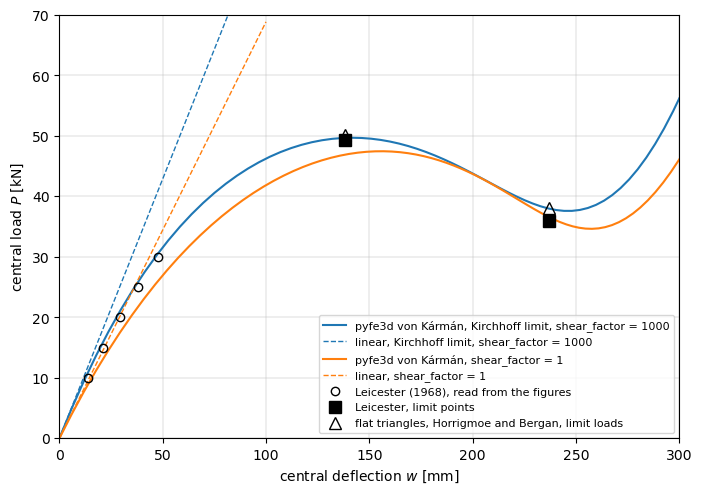

In [16]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for (k, p), c in zip(leic_paths.items(), ['C0', 'C1', 'C2', 'C3']):
    ax.plot(p['w'], p['F'], '-', color=c, lw=1.5, label='pyfe3d %s, %s' % k)
    ax.plot([0, 100], [0, 100*p['slope']], '--', color=c, lw=1, label='linear, %s' % k[1])
ax.plot(LEICESTER_RISING[:, 1], LEICESTER_RISING[:, 0], 'ko', mfc='none',
        label='Leicester (1968), read from the figures')
ax.plot(*LEICESTER_UPPER[::-1], 'ks', ms=8, label='Leicester, limit points')
ax.plot(*LEICESTER_LOWER[::-1], 'ks', ms=8)
ax.plot([LEICESTER_UPPER[1], LEICESTER_LOWER[1]], HORRIGMOE_LIMIT_LOADS, 'k^',
        mfc='none', ms=8, label='flat triangles, Horrigmoe and Bergan, limit loads')
ax.set_xlim(0, 300)
ax.set_ylim(0, 70)
ax.set_xlabel('central deflection $w$ [mm]')
ax.set_ylabel('central load $P$ [kN]')
ax.legend(loc='lower right', fontsize=8)
ax.grid(True, lw=0.3)
plt.show()

In the Kirchhoff limit, with 32x32 cells, the upper limit load is 49.70 kN
at 141.6 mm, 0.9 % above Leicester's 49.25 kN at 138 mm, and the lower one
37.61 kN at 248.0 mm, 4.5 % above Leicester's 36.0 kN at 237 mm, between
Leicester and the flat triangles of Horrigmoe and Bergan (38.1 kN): both
within their tolerances. The deflection of the upper limit point agrees
within the reading uncertainty of 5 mm; that of the lower one is 11 mm
larger. On the rising branch, the Kirchhoff limit is 9 % above
Leicester's curve at 10 kN, decreasing to 2 % at 30 kN; the flat triangles
of Horrigmoe and Bergan are stiffer still there, with 10 kN at about
11.4 mm against 13.9 mm for Leicester, a scatter of the references of the
same order. The largest rotation along the line $Y = 0$ is 14 degrees at
the upper limit point, 22 degrees at the lower one and 27 degrees at
$w = 300$ mm: the snap-through stays in the range of moderate rotations,
which is also that of the shallow shell theory of the references.

With the actual transverse shear stiffness the shell is more flexible: the
limit loads are 3.6 and 3.8 % below Leicester's, at 19 and 21 mm larger
deflections, and this path still changes with the mesh, see the linear
stiffness above.

Mesh convergence of the Kirchhoff limit:

In [17]:
print('%6s %22s %22s' % ('cells', 'upper limit [kN, mm]', 'lower limit [kN, mm]'))
for n in [8, 16]:
    q = leicester_path(n, 1000.)
    (Pu_, wu_), (Pl_, wl_) = limit_points(q['w'], q['F'], 190.)
    print('%3dx%-2d %12.2f %8.1f %12.2f %8.1f' % (n, n, Pu_, wu_, Pl_, wl_))
print('%3dx%-2d %12.2f %8.1f %12.2f %8.1f' % (32, 32, Pu, wu, Pl, wl))

 cells   upper limit [kN, mm]   lower limit [kN, mm]


  8x8         52.25    143.7        45.69    232.9


 16x16        50.22    142.3        39.50    243.2
 32x32        49.70    141.6        37.61    248.0


The limit loads of the Kirchhoff limit converge from above. Measured
separately on 2026-10-30: 64x64 cells of `Tria3R` give 49.57 kN at
141.2 mm and 37.09 kN at 246.7 mm, +0.6 and +3.0 % of Leicester; 32x32
`Quad4`, 49.63 and 37.21 kN (re-measured on 2026-10-31 with the MITC4
transverse shear of `Quad4`: unchanged); restraining also the rotation of the edges
about their normal in the tangent plane, a hard simple support, changes
them by less than 0.1 %.

Large rotations: the co-rotational kinematics
---

The same comparison with `Quad4R` and `kinematics='corotational'`, 16x16
cells in the Kirchhoff limit, with the von Kármán path of `Quad4R` on the
same mesh; the tolerances are those of the limit loads above.

co-rotational, 16x16 Quad4R: 65 increments, 9 s


co-rotational, Quad4R      upper limit 50.38 kN at 136.7 mm (+2.3 %), lower limit 37.73 kN at 240.1 mm (+4.8 %); largest rotation 26.9 deg
von Kármán, Quad4R         upper limit 49.95 kN at 141.8 mm (+1.4 %), lower limit 38.09 kN at 245.3 mm (+5.8 %); largest rotation 27.1 deg


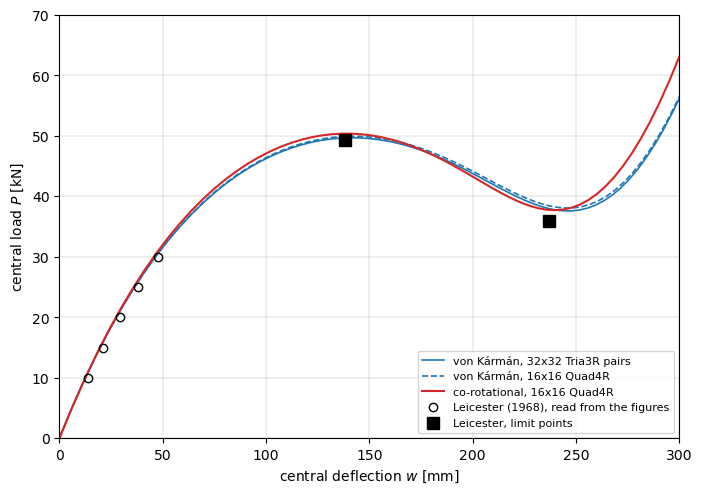

In [18]:
t0 = time.time()
p = FORMULATIONS['co-rotational']['leicester'](16, 1000.)
leic_cr = p
print('co-rotational, 16x16 Quad4R: %d increments, %.0f s' % (len(p['an'].increments), time.time() - t0))
q = leicester_path(16, 1000., element='Quad4R')
for label, r_ in [('co-rotational, Quad4R', p), ('von Kármán, Quad4R', q)]:
    assert r_['an'].increments[-1] == 1.
    assert np.all(np.diff(r_['w']) > 0)
    (Pu_, wu_), (Pl_, wl_) = limit_points(r_['w'], r_['F'], 190.)
    r_['limits'] = (Pu_, wu_), (Pl_, wl_)
    print('%-26s upper limit %.2f kN at %.1f mm (%+.1f %%), lower limit %.2f kN at '
          '%.1f mm (%+.1f %%); largest rotation %.1f deg' % (label, Pu_, wu_,
          100*(Pu_/LEICESTER_UPPER[0] - 1), Pl_, wl_, 100*(Pl_/LEICESTER_LOWER[0] - 1),
          r_['rot'].max()))
(Pu_, wu_), (Pl_, wl_) = p['limits']
assert abs(Pu_/LEICESTER_UPPER[0] - 1) < TOL_UPPER
assert abs(Pl_/LEICESTER_LOWER[0] - 1) < TOL_LOWER

fig, ax = plt.subplots(figsize=(8, 5.5))
pv = leic_paths['von Kármán', 'Kirchhoff limit, shear_factor = 1000']
ax.plot(pv['w'], pv['F'], 'C0-', lw=1.2, label='%s, 32x32 Tria3R pairs' % 'von Kármán')
ax.plot(q['w'], q['F'], 'C0--', lw=1.2, label='%s, 16x16 Quad4R' % 'von Kármán')
ax.plot(p['w'], p['F'], 'C3-', lw=1.5, label='co-rotational, 16x16 Quad4R')
ax.plot(LEICESTER_RISING[:, 1], LEICESTER_RISING[:, 0], 'ko', mfc='none',
        label='Leicester (1968), read from the figures')
ax.plot(*LEICESTER_UPPER[::-1], 'ks', ms=8, label='Leicester, limit points')
ax.plot(*LEICESTER_LOWER[::-1], 'ks', ms=8)
ax.set_xlim(0, 300)
ax.set_ylim(0, 70)
ax.set_xlabel('central deflection $w$ [mm]')
ax.set_ylabel('central load $P$ [kN]')
ax.legend(loc='lower right', fontsize=8)
ax.grid(True, lw=0.3)
plt.show()

The rotations of this shell stay below 27 degrees, and the co-rotational
path is close to the von Kármán one with the same element and mesh: the
upper limit load 0.9 % higher, 50.38 against 49.95 kN, and the lower one
0.9 % lower, 37.73 against 38.09 kN, both within the tolerances of
Leicester's solution, +2.3 % and +4.8 %. On this shallow shell the
von Kármán strains are adequate, as concluded above; the 16x16 `Quad4R`
mesh is coarser than the 32x32 `Tria3R` pairs, whose von Kármán limit
loads are +0.9 and +4.5 %.

Summary
---

| case | reference | pyfe3d, von Kármán strains | pyfe3d, co-rotational, `Quad4R` |
|---|---|---|---|
| cap, $w/t_h \le 6.72$, rotations up to 30 degrees | Tables 3 and 4 | within 1.2 %, both radii, 16x16 cells | within 2.1 %, 12x12 cells |
| cap, $w/t_h = 13.6$ to 20.9, 50 to 68 degrees | Tables 3 and 4 | 7 to 21 % below | within 2.5 % |
| cap inverted, $w/t_h = 28.7$, 79 to 86 degrees | $F_n = 3.705$ | 1.74, no stiffening | 3.12, stiffening, -15.9 %; $w/t_h = 29.26$ at $F_n = 3.705$, +2.0 % |
| hinged shell, upper limit load, 14 degrees | Leicester, 49.25 kN | 49.70 kN, +0.9 %, Kirchhoff limit, 32x32 cells | 50.38 kN, +2.3 %, 16x16 cells |
| hinged shell, lower limit load, 22 degrees | Leicester, 36.0 kN | 37.61 kN, +4.5 % | 37.73 kN, +4.8 % |

- The solver traces both paths with the deflection prescribed through `bu`
  and `uk` and `calc_fext` returning zeros; the reaction is `calc_fint(u)`
  at the known dof, and the linear one $\boldsymbol{K}_{C0} \boldsymbol{u}$.
- Cap geometry: with the mid-surface radius $a + t_h/2$, COMSOL's shell
  geometry, the loads are about 1 % lower than with $a$; the difference is
  smaller than the scatter of the published results, so this comparison
  does not tell which radius the reference used; both agree with it within
  the tolerance where the rotations are moderate.
- Beyond rotations of about 30 degrees the von Kármán strains no longer
  represent the cap, and the computed path reproduces neither the limit
  load nor the stiffening of the inverted cap. The co-rotational kinematics
  follow the reference within 2.5 % up to $w/t_h = 20.887$, at rotations of
  57 degrees, and reproduce the stiffening of the inverted cap; their limit
  load converges with the mesh, to about 1.845 against 1.806 for COMSOL and
  1.835 for an axisymmetric model; just past it the quarter model leaves the
  axisymmetric path through a $\cos 2\varphi$ mode, with a snap-back of the
  prescribed deflection, and the load at the point after the maximum is
  8 % above the reference; at the load of the last point the deflection is
  within 2 % of the reference. The hinged shallow shell
  snaps through within rotations below 30 degrees and agrees with
  Leicester's shallow-shell solution in the Kirchhoff limit.